In [2]:
from google.colab import files
import pandas as pd
import io
uploaded = files.upload()

# Get the filename
filename = list(uploaded.keys())[0]

# Load the CSV into a DataFrame
df = pd.read_csv(io.BytesIO(uploaded[filename]))
display(df.head())

Saving MobileSales.csv to MobileSales.csv


,Brands,Models,Colors,Mobile,Memory,Storage,Selling Price,Original Price,Discount,Rating
0,SAMSUNG,GALAXY M31S,Mirage Black,SAMSUNG GALAXY M31S,8,128,19330,20999,1669,4.3
1,Nokia,3.2,Steel,Nokia 3.2,2,16,10199,10199,0,3.8
2,realme,C2,Diamond Black,realme C2,2,89,6999,7999,1000,4.4
3,Infinix,Note 5,Ice Blue,Infinix Note 5,4,64,12999,12999,0,4.2
4,Apple,iPhone 11,Black,Apple iPhone 11,4,64,49900,49900,0,4.6


=== Q1: Highest Model Count -> SAMSUNG (719 models) ===


,Brand,Model_Count
0,SAMSUNG,719
1,Apple,387
2,realme,327
3,OPPO,260
4,Nokia,213
5,Xiaomi,198
6,Infinix,151
7,GIONEE,129
8,vivo,124
9,Lenovo,121



=== Q2: Top 10 Mobile Models by Selling Price ===


,Brands,Models,Storage_GB,Selling Price
1079,Apple,iPhone 13 Pro Max,89,179900
323,Apple,iPhone 13 Pro Max,1,179900
923,SAMSUNG,Fold 2 5G,256,169999
1974,Apple,iPhone 13 Pro Max,1,169900
729,Apple,iPhone 13 Pro,1,169900
767,Apple,iPhone 13 Pro Max,512,159900
1626,SAMSUNG,Galaxy Z Fold3 5G,512,157999
643,Apple,iPhone 11 Pro Max,512,150800
760,SAMSUNG,Galaxy Z Fold3 5G,256,149999
1595,SAMSUNG,Galaxy Fold 2,256,149999



=== Q3: Average Selling Price per Brand ===


,Brands,Avg_Selling_Price
1,Apple,81985.560724
3,Google Pixel,61391.862069
5,IQOO,37190.000000
4,HTC,28314.381818
13,SAMSUNG,24296.248957
16,vivo,23866.241935
0,ASUS,20326.915254
7,LG,19323.181818
11,OPPO,18560.488462
14,Xiaomi,16941.909091


... (10 outputs left out)


=== Q9: Top 10 Value for Money Models ===


,Brands,Models,Memory_GB,Storage_GB,Selling Price,Discount_Percentage,Rating,Value_Score
1795,SAMSUNG,Guru Plus B110,512.0,512,1700,0.000000,4.2,0.799306
650,Lenovo,A269i,512.0,512,5499,0.000000,3.7,0.740565
32,SAMSUNG,Galaxy Note 9,8.0,512,49999,0.000000,4.6,0.704688
390,ASUS,ROG Phone II,12.0,512,62999,0.000000,4.6,0.694571
287,Apple,iPhone 13 mini,4.0,512,94900,5.005005,4.6,0.670593
76,SAMSUNG,Galaxy S10,8.0,512,92000,0.000000,4.6,0.669472
1541,SAMSUNG,Galaxy Note 10 Plus,12.0,512,95000,0.000000,4.6,0.667739
247,vivo,X50,8.0,256,44990,0.000000,5.0,0.653137
3106,ASUS,ROG Phone 5 Pro,16.0,512,69999,7.894841,4.2,0.651877
1655,vivo,X60 Pro,12.0,256,48780,0.000000,5.0,0.650741



=== Q10: Correlation with 'Good Product' (Rating >= 4.0) ===


,Correlation_with_Good_Product
Good_Product,1.000000
Rating,0.730531
Storage_GB,0.220294
Selling Price,0.182886
Discount_Percentage,0.042607
Memory_GB,-0.240195


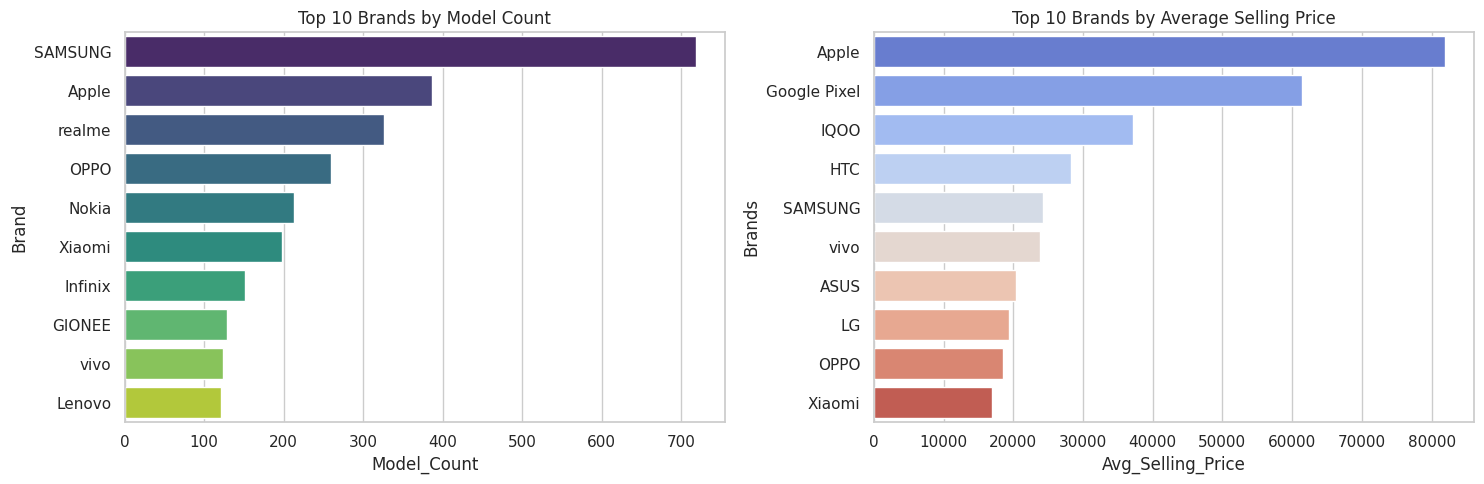

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

# Load dataset
df = pd.read_csv('MobileSales.csv')

# --- DATA CLEANING ---
df['Brands'] = df['Brands'].astype(str).str.strip()
df['Models'] = df['Models'].astype(str).str.strip()
df['Memory_GB'] = pd.to_numeric(df['Memory'].astype(str).str.strip(), errors='coerce')
df['Storage_GB'] = pd.to_numeric(df['Storage'], errors='coerce')
df['Discount_Amount'] = df['Original Price'] - df['Selling Price']
df['Discount_Percentage'] = (df['Discount_Amount'] / df['Original Price']) * 100

# 1. Brand with Highest Number of Mobile Models
brand_counts = df['Brands'].value_counts().reset_index()
brand_counts.columns = ['Brand', 'Model_Count']
print(f"=== Q1: Highest Model Count -> {brand_counts.iloc[0]['Brand']} ({brand_counts.iloc[0]['Model_Count']} models) ===")
display(brand_counts)

# 2. Top 10 Mobile Models by Selling Price
top_10_price = (
    df[['Brands', 'Models', 'Storage_GB', 'Selling Price']]
    .drop_duplicates()
    .sort_values(by='Selling Price', ascending=False)
    .head(10)
)
print("\n=== Q2: Top 10 Mobile Models by Selling Price ===")
display(top_10_price)

# 3. Average Selling Price per Brand
avg_price_brand = (
    df.groupby('Brands', as_index=False)['Selling Price'].mean()
    .rename(columns={'Selling Price': 'Avg_Selling_Price'})
    .sort_values(by='Avg_Selling_Price', ascending=False)
)
print("\n=== Q3: Average Selling Price per Brand ===")
display(avg_price_brand)

# 4. Brand Offering Highest Average Discount
avg_discount_brand = (
    df.groupby('Brands', as_index=False)
    .agg(Avg_Discount_Amount=('Discount_Amount', 'mean'), Avg_Discount_Pct=('Discount_Percentage', 'mean'))
    .sort_values(by='Avg_Discount_Amount', ascending=False)
)
print("\n=== Q4: Average Discount by Brand ===")
display(avg_discount_brand)

# 5. Brands with Highest Average Customer Rating vs Average Selling Price
brand_rating_price = (
    df.groupby('Brands', as_index=False)
    .agg(Avg_Rating=('Rating', 'mean'), Avg_Selling_Price=('Selling Price', 'mean'))
    .sort_values(by='Avg_Rating', ascending=False)
)
print("\n=== Q5: Average Rating & Selling Price Comparison ===")
display(brand_rating_price)

# 6. How Storage Capacity Affects Average Selling Price (FIXED: uses Storage_GB, not Memory)
storage_price = (
    df.groupby('Storage_GB', as_index=False)
    .agg(Avg_Selling_Price=('Selling Price', 'mean'), Model_Count=('Models', 'count'))
    .sort_values(by='Storage_GB')
)
print("\n=== Q6: Storage Capacity vs Average Selling Price ===")
display(storage_price)

# 7. Models with Highest Discount Amount & Discount Percentage
top_discounts = (
    df[['Brands', 'Models', 'Original Price', 'Selling Price', 'Discount_Amount', 'Discount_Percentage']]
    .drop_duplicates()
    .sort_values(by='Discount_Amount', ascending=False)
    .head(10)
)
print("\n=== Q7: Top 10 Models by Discount Amount ===")
display(top_discounts)

# 8. Best Memory & Storage Combination (Balance Between Price & Rating)
combo_stats = (
    df.dropna(subset=['Memory_GB', 'Storage_GB'])
    .groupby(['Memory_GB', 'Storage_GB'], as_index=False)
    .agg(Avg_Price=('Selling Price', 'mean'), Avg_Rating=('Rating', 'mean'), Count=('Models', 'count'))
)
combo_stats = combo_stats[combo_stats['Count'] >= 5].copy()
combo_stats['Balance_Score'] = (combo_stats['Avg_Rating'] / combo_stats['Avg_Price']) * 10000
print("\n=== Q8: Best Memory + Storage Combinations ===")
display(combo_stats.sort_values(by='Balance_Score', ascending=False).head(10))

# 9. Top 10 Value for Money Models (FIXED: uses both Storage_GB and Memory_GB properly)
# Value Score = 0.30*Norm_Rating + 0.20*Norm_Discount% + 0.20*Norm_Storage + 0.15*Norm_Memory + 0.15*(1 - Norm_Price)
val_df = df.dropna(subset=['Memory_GB', 'Storage_GB']).copy()
scaler = MinMaxScaler()
for col, norm_col in [
    ('Rating', 'norm_rating'),
    ('Selling Price', 'norm_price'),
    ('Discount_Percentage', 'norm_discount'),
    ('Storage_GB', 'norm_storage'),
    ('Memory_GB', 'norm_memory')
]:
    val_df[norm_col] = scaler.fit_transform(val_df[[col]])

val_df['Value_Score'] = (
    val_df['norm_rating'] * 0.30 +
    val_df['norm_discount'] * 0.20 +
    val_df['norm_storage'] * 0.20 +
    val_df['norm_memory'] * 0.15 +
    (1 - val_df['norm_price']) * 0.15
)

top_10_value = (
    val_df[['Brands', 'Models', 'Memory_GB', 'Storage_GB', 'Selling Price', 'Discount_Percentage', 'Rating', 'Value_Score']]
    .drop_duplicates(subset=['Brands', 'Models'])
    .sort_values(by='Value_Score', ascending=False)
    .head(10)
)
print("\n=== Q9: Top 10 Value for Money Models ===")
display(top_10_value)

# 10. Factors Determining a "Good Product" (Rating >= 4.0)
df['Good_Product'] = (df['Rating'] >= 4.0).astype(int)
corr_cols = ['Rating', 'Storage_GB', 'Selling Price', 'Discount_Percentage', 'Memory_GB', 'Good_Product']
correlations = df[corr_cols].corr()['Good_Product'].sort_values(ascending=False)
print("\n=== Q10: Correlation with 'Good Product' (Rating >= 4.0) ===")
display(correlations.to_frame(name='Correlation_with_Good_Product'))

# --- CHARTS FOR PPT ---
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=brand_counts.head(10), x='Model_Count', y='Brand', ax=axes[0], hue='Brand', palette='viridis', legend=False)
axes[0].set_title('Top 10 Brands by Model Count')

sns.barplot(data=avg_price_brand.head(10), x='Avg_Selling_Price', y='Brands', ax=axes[1], hue='Brands', palette='coolwarm', legend=False)
axes[1].set_title('Top 10 Brands by Average Selling Price')

plt.tight_layout()
plt.show()